# Module 4 – Regression Analysis

## Parent–Young Adult Independence in the United States

### Objective

The goal of this notebook is to explore the impact of parental
interaction, socioeconomic, and demographic factors on young
adulthood independence by using linear regression and logistic
regression.

The goals are to:

- Get data ready for regression and classification tasks.
- Define numeric targets for the regression task.
- Define binary target for the logistic regression task.
- Split data into training and testing datasets.
- Train and evaluate regression models.
- Understand the meaning of regression coefficients.
- Compare logistic regression with Naive Bayes from Module 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

import os

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Data Loading and Inspection

The datasets prepared in previous project modules are loaded
and examined to identify appropriate predictor variables and
target variables for linear and logistic regression.

In [2]:
base_url = "https://raw.githubusercontent.com/swejal22/parent-child-independence-project/main/"

# Load the labeled dataset from Module 3
df_nb = pd.read_csv(base_url + "nb_labeled_data.csv")

print("Dataset shape:", df_nb.shape)

print("\nColumn names:")
print(df_nb.columns.tolist())

print("\nData types:")
print(df_nb.dtypes)

print("\nMissing values:")
print(df_nb.isnull().sum())

print("\nDataset preview:")
display(df_nb.head())

Dataset shape: (1478, 7)

Column names:
['received_financial_help', 'lives_with_parents', 'parent_involvement_level', 'communication_satisfaction', 'employment_status', 'age_group', 'financial_independence']

Data types:
received_financial_help       float64
lives_with_parents            float64
parent_involvement_level      float64
communication_satisfaction    float64
employment_status             float64
age_group                       int64
financial_independence        float64
dtype: object

Missing values:
received_financial_help       0
lives_with_parents            0
parent_involvement_level      0
communication_satisfaction    0
employment_status             0
age_group                     0
financial_independence        0
dtype: int64

Dataset preview:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group,financial_independence
0,1.0,1.0,1.0,3.0,2.0,1,2.0
1,2.0,3.0,3.0,3.0,1.0,1,1.0
2,2.0,3.0,3.0,3.0,2.0,2,1.0
3,2.0,3.0,3.0,2.0,1.0,1,4.0
4,1.0,3.0,3.0,1.0,1.0,2,2.0


## 2. Feature and Target Variable Inspection

Examine the unique values and frequency distributions of
each variable to identify appropriate features and target
variables for linear and binary logistic regression.

In [3]:
for col in df_nb.columns:
    print("=" * 65)
    print("Column:", col)
    print("Unique values:", sorted(df_nb[col].unique()))
    print("\nValue counts:")
    print(df_nb[col].value_counts().sort_index())
    print()

Column: received_financial_help
Unique values: [np.float64(1.0), np.float64(2.0)]

Value counts:
received_financial_help
1.0    571
2.0    907
Name: count, dtype: int64

Column: lives_with_parents
Unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]

Value counts:
lives_with_parents
1.0     216
2.0     147
3.0    1115
Name: count, dtype: int64

Column: parent_involvement_level
Unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]

Value counts:
parent_involvement_level
1.0     121
2.0     316
3.0    1041
Name: count, dtype: int64

Column: communication_satisfaction
Unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]

Value counts:
communication_satisfaction
1.0     83
2.0    403
3.0    992
Name: count, dtype: int64

Column: employment_status
Unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]

Value counts:
employment_status
1.0    1023
2.0     212
3.0     216
4.0      25
5.0       2
Name: count,

In [4]:
df_clean = pd.read_csv(
    base_url + "pew_young_adults_clean_numeric.csv"
)

print("Dataset shape:", df_clean.shape)

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nDataset preview:")
display(df_clean.head())

print("\nDescriptive statistics:")
display(df_clean.describe().T)

Dataset shape: (1495, 30)

Column names:
['respondent_id', 'survey_weight', 'school_enrollment', 'employment_status', 'prepared_for_independence', 'advice_finances', 'advice_career', 'advice_mental_health', 'advice_physical_health', 'advice_friendships', 'relies_on_parents_emotionally', 'phone_video_frequency', 'text_frequency', 'in_person_frequency', 'financial_independence', 'received_financial_help', 'lives_with_parents', 'relationship_rating', 'true_self_with_parent', 'parent_relies_on_child_emotionally', 'knows_parent_beyond_parent_role', 'parent_involvement_level', 'communication_satisfaction', 'age_group', 'gender', 'education_level', 'race_ethnicity', 'marital_status', 'income_tier', 'census_region']

Dataset preview:


,respondent_id,survey_weight,school_enrollment,employment_status,prepared_for_independence,advice_finances,advice_career,advice_mental_health,advice_physical_health,advice_friendships,...,knows_parent_beyond_parent_role,parent_involvement_level,communication_satisfaction,age_group,gender,education_level,race_ethnicity,marital_status,income_tier,census_region
0,102198,0.362393,3.0,2.0,1.0,1.0,1.0,2.0,4.0,1.0,...,1.0,1.0,3.0,1,2.0,1.0,1.0,6.0,1.0,1.0
1,274825,1.681402,4.0,1.0,2.0,1.0,2.0,3.0,2.0,3.0,...,1.0,3.0,3.0,1,1.0,1.0,1.0,6.0,3.0,4.0
2,278114,0.396099,4.0,2.0,1.0,5.0,5.0,5.0,4.0,5.0,...,2.0,3.0,3.0,2,2.0,1.0,1.0,1.0,1.0,2.0
3,309053,3.588310,4.0,1.0,1.0,3.0,2.0,4.0,3.0,4.0,...,3.0,3.0,2.0,1,1.0,1.0,1.0,2.0,2.0,4.0
4,319198,0.321208,4.0,1.0,4.0,3.0,4.0,5.0,5.0,5.0,...,4.0,3.0,1.0,2,1.0,1.0,1.0,6.0,2.0,2.0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
respondent_id,1495.0,1.919762e+11,4.382426e+10,102198.000000,2.018011e+11,2.019011e+11,2.022010e+11,2.023010e+11
survey_weight,1495.0,1.000000e+00,1.229374e+00,0.018204,2.655565e-01,5.233511e-01,1.154605e+00,6.319163e+00
school_enrollment,1495.0,3.749164e+00,5.308025e-01,2.000000,4.000000e+00,4.000000e+00,4.000000e+00,4.000000e+00
employment_status,1492.0,1.492627e+00,8.119327e-01,1.000000,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+00
prepared_for_independence,1494.0,2.044177e+00,1.054155e+00,1.000000,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
advice_finances,1494.0,3.115127e+00,1.182083e+00,1.000000,2.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00
advice_career,1494.0,3.038153e+00,1.204709e+00,1.000000,2.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00
advice_mental_health,1493.0,3.567984e+00,1.178548e+00,1.000000,3.000000e+00,4.000000e+00,5.000000e+00,5.000000e+00
advice_physical_health,1494.0,3.254351e+00,1.162989e+00,1.000000,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00
advice_friendships,1492.0,3.581099e+00,1.146887e+00,1.000000,3.000000e+00,4.000000e+00,5.000000e+00,5.000000e+00


In [5]:
print("Financial Independence Distribution:")
print(df_nb["financial_independence"].value_counts().sort_index())

print("\nUnique Values for Each Feature:")

for col in df_nb.columns:
    print(col, ":", sorted(df_nb[col].unique()))

Financial Independence Distribution:
financial_independence
1.0    786
2.0    338
3.0    163
4.0    117
5.0     74
Name: count, dtype: int64

Unique Values for Each Feature:
received_financial_help : [np.float64(1.0), np.float64(2.0)]
lives_with_parents : [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
parent_involvement_level : [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
communication_satisfaction : [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
employment_status : [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
age_group : [np.int64(1), np.int64(2)]
financial_independence : [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


In [6]:
df_labeled = pd.read_csv(
    base_url + "pew_young_adults_eda_labeled.csv"
)

print("Dataset shape:", df_labeled.shape)

print("\nColumn names:")
print(df_labeled.columns.tolist())

print("\nFinancial Independence Labels:")
print(df_labeled["financial_independence"].value_counts())

Dataset shape: (1495, 30)

Column names:
['respondent_id', 'survey_weight', 'school_enrollment', 'employment_status', 'prepared_for_independence', 'advice_finances', 'advice_career', 'advice_mental_health', 'advice_physical_health', 'advice_friendships', 'relies_on_parents_emotionally', 'phone_video_frequency', 'text_frequency', 'in_person_frequency', 'financial_independence', 'received_financial_help', 'lives_with_parents', 'relationship_rating', 'true_self_with_parent', 'parent_relies_on_child_emotionally', 'knows_parent_beyond_parent_role', 'parent_involvement_level', 'communication_satisfaction', 'age_group', 'gender', 'education_level', 'race_ethnicity', 'marital_status', 'income_tier', 'census_region']

Financial Independence Labels:
financial_independence
Completely    792
Mostly        341
Somewhat      165
A little      119
Not at all     74
Name: count, dtype: int64


In [7]:
# Match numeric codes with original survey labels
coding_check = df_clean[
    ["respondent_id", "financial_independence"]
].merge(
    df_labeled[
        ["respondent_id", "financial_independence"]
    ],
    on="respondent_id",
    suffixes=("_numeric", "_label"),
    validate="one_to_one"
)

display(pd.crosstab(
    coding_check["financial_independence_numeric"],
    coding_check["financial_independence_label"]
))

financial_independence_label,A little,Completely,Mostly,Not at all,Somewhat
financial_independence_numeric,,,,,
1.0,0,792,0,0,0
2.0,0,0,341,0,0
3.0,0,0,0,0,165
4.0,119,0,0,0,0
5.0,0,0,0,74,0


## 3. Target Variable Preparation

Two dependent variables are developed for the regression analysis:

### Linear Regression
The five-category variable measuring financial independence is
reversed so that the higher the score, the higher the
degree of financial independence.

### Logistic Regression
The five-category variable of financial independence is transformed
into two categories:

- Category 1: Completely or largely financially independent.
- Category 0: Somewhat, slightly, or not financially independent.

The numerical value is an ordinal scale used as a quantitative
variable in linear regression. The binary classification is a choice
for this analysis.

In [8]:
# Create a copy of the Module 3 dataset
df_reg = df_nb.copy()

# Linear regression target
df_reg["independence_score"] = (
    6 - df_reg["financial_independence"]
).astype(int)

# Logistic regression target
df_reg["independence_binary"] = (
    df_reg["financial_independence"] <= 2
).astype(int)

print("Dataset shape:", df_reg.shape)

print("\nLinear Regression Target Distribution:")
print(df_reg["independence_score"].value_counts().sort_index())

print("\nLogistic Regression Target Distribution:")
print(df_reg["independence_binary"].value_counts().sort_index())

print("\nBinary Class Proportions (%):")
print(df_reg["independence_binary"].value_counts(
    normalize=True
).sort_index() * 100)

display(df_reg.head())

Dataset shape: (1478, 9)

Linear Regression Target Distribution:
independence_score
1     74
2    117
3    163
4    338
5    786
Name: count, dtype: int64

Logistic Regression Target Distribution:
independence_binary
0     354
1    1124
Name: count, dtype: int64

Binary Class Proportions (%):
independence_binary
0    23.951286
1    76.048714
Name: proportion, dtype: float64


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group,financial_independence,independence_score,independence_binary
0,1.0,1.0,1.0,3.0,2.0,1,2.0,4,1
1,2.0,3.0,3.0,3.0,1.0,1,1.0,5,1
2,2.0,3.0,3.0,3.0,2.0,2,1.0,5,1
3,2.0,3.0,3.0,2.0,1.0,1,4.0,2,0
4,1.0,3.0,3.0,1.0,1.0,2,2.0,4,1


## 4. Feature Selection and Train-Test Split

In total, six predictor variables are chosen to examine the
factors associated with financial independence among the youth.

A split of 80% training data and 20% testing data is performed,
where the process utilizes stratified sampling and a random seed
value of 42.

The training and testing datasets are separate from each other in
order to prevent any information leakage.

All the target variables have been filtered out of the predictors.

In [9]:
# Select predictor variables
features = [
    "received_financial_help",
    "lives_with_parents",
    "parent_involvement_level",
    "communication_satisfaction",
    "employment_status",
    "age_group"
]

X = df_reg[features].copy()


y_linear = df_reg["independence_score"]
y_logistic = df_reg["independence_binary"]


train_idx, test_idx = train_test_split(
    df_reg.index,
    test_size=0.20,
    random_state=42,
    stratify=y_logistic
)


X_train = X.loc[train_idx].copy()
X_test = X.loc[test_idx].copy()


y_linear_train = y_linear.loc[train_idx]
y_linear_test = y_linear.loc[test_idx]


y_logistic_train = y_logistic.loc[train_idx]
y_logistic_test = y_logistic.loc[test_idx]


overlap = set(train_idx).intersection(set(test_idx))
assert len(overlap) == 0

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Overlapping observations:", len(overlap))

print("\nTraining class distribution (%):")
print(y_logistic_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution (%):")
print(y_logistic_test.value_counts(normalize=True) * 100)

print("\nTraining data sample:")
display(X_train.head())

print("\nTesting data sample:")
display(X_test.head())

Training set shape: (1182, 6)
Testing set shape: (296, 6)
Overlapping observations: 0

Training class distribution (%):
independence_binary
1    76.05753
0    23.94247
Name: proportion, dtype: float64

Testing class distribution (%):
independence_binary
1    76.013514
0    23.986486
Name: proportion, dtype: float64

Training data sample:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group
74,1.0,3.0,3.0,3.0,2.0,1
1058,1.0,3.0,3.0,1.0,1.0,2
243,2.0,3.0,3.0,3.0,1.0,2
261,2.0,3.0,3.0,3.0,1.0,2
528,2.0,3.0,3.0,3.0,1.0,2



Testing data sample:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group
1057,1.0,3.0,2.0,3.0,3.0,2
164,2.0,3.0,1.0,1.0,2.0,2
806,1.0,1.0,3.0,3.0,3.0,1
43,2.0,3.0,3.0,3.0,1.0,2
1093,2.0,2.0,3.0,3.0,3.0,1


## 5. Categorical Feature Encoding

The six predictive features consist of categorical
survey answers represented numerically.

The one hot encoding technique is used to transform these
categorical values into binary values. Each feature has one
category selected as the reference category and not included
in the set of binary predictor variables to avoid perfect
multicollinearity.

The encoder is trained on the training set and then
transformed on the test set.

In [10]:
from sklearn.preprocessing import OneHotEncoder


encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)


X_train_encoded = encoder.fit_transform(X_train)


X_test_encoded = encoder.transform(X_test)


encoded_features = encoder.get_feature_names_out(features)


X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_features,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_features,
    index=X_test.index
)

print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

print("\nEncoded feature names:")
print(encoded_features.tolist())

print("\nEncoded training sample:")
display(X_train_encoded.head())

print("\nEncoded testing sample:")
display(X_test_encoded.head())

Original training shape: (1182, 6)
Encoded training shape: (1182, 12)
Encoded testing shape: (296, 12)

Encoded feature names:
['received_financial_help_2.0', 'lives_with_parents_2.0', 'lives_with_parents_3.0', 'parent_involvement_level_2.0', 'parent_involvement_level_3.0', 'communication_satisfaction_2.0', 'communication_satisfaction_3.0', 'employment_status_2.0', 'employment_status_3.0', 'employment_status_4.0', 'employment_status_5.0', 'age_group_2']

Encoded training sample:


,received_financial_help_2.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_2.0,parent_involvement_level_3.0,communication_satisfaction_2.0,communication_satisfaction_3.0,employment_status_2.0,employment_status_3.0,employment_status_4.0,employment_status_5.0,age_group_2
74,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1058,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
243,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
261,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
528,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0



Encoded testing sample:


,received_financial_help_2.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_2.0,parent_involvement_level_3.0,communication_satisfaction_2.0,communication_satisfaction_3.0,employment_status_2.0,employment_status_3.0,employment_status_4.0,employment_status_5.0,age_group_2
1057,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
164,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
806,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
43,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1093,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


## 6. Saving Prepared Datasets

All these datasets, which are prepared, labeled, training,
testing and one-hot encoded, have been exported in the form of CSV files.

Target variables for both datasets are available in the exported files but are not part of the predictors.

In [11]:
# Create the complete prepared dataset
regression_data = df_reg[
    features + ["independence_score", "independence_binary"]
].copy()

# Create labeled training and testing datasets
regression_train = regression_data.loc[train_idx].copy()
regression_test = regression_data.loc[test_idx].copy()

# Create encoded labeled datasets
encoded_train = X_train_encoded.copy()
encoded_train["independence_score"] = y_linear_train
encoded_train["independence_binary"] = y_logistic_train

encoded_test = X_test_encoded.copy()
encoded_test["independence_score"] = y_linear_test
encoded_test["independence_binary"] = y_logistic_test


regression_data.to_csv(
    "regression_labeled_data.csv", index=False
)

regression_train.to_csv(
    "regression_training_data.csv", index=False
)

regression_test.to_csv(
    "regression_testing_data.csv", index=False
)

encoded_train.to_csv(
    "regression_encoded_training_data.csv", index=False
)

encoded_test.to_csv(
    "regression_encoded_testing_data.csv", index=False
)

print("All datasets saved successfully!")

print("\nComplete dataset:", regression_data.shape)
print("Training dataset:", regression_train.shape)
print("Testing dataset:", regression_test.shape)
print("Encoded training dataset:", encoded_train.shape)
print("Encoded testing dataset:", encoded_test.shape)

All datasets saved successfully!

Complete dataset: (1478, 8)
Training dataset: (1182, 8)
Testing dataset: (296, 8)
Encoded training dataset: (1182, 14)
Encoded testing dataset: (296, 14)


## 7. Data Preparation Visualizations

Visual representation of the whole labeled dataset,
training dataset, and testing dataset is done using Python.

The visual representations showcase the format of the
prepared datasets, including the predictors and the two target
variables.

Another visual representation showing the before and after
formatting of the categorical survey responses to binary indicator
variables is also generated.

In [12]:
def save_table_image(data, title, filename, n_rows=6):

    sample = data.head(n_rows).copy()


    sample.columns = [
        col.replace("_", "\n")
        for col in sample.columns
    ]

    fig, ax = plt.subplots(
        figsize=(max(14, len(sample.columns) * 2), 4)
    )

    ax.axis("off")

    table = ax.table(
        cellText=sample.values,
        colLabels=sample.columns,
        cellLoc="center",
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 2.8)


    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#D1D5DB")

        if row == 0:
            cell.set_facecolor("#24476B")
            cell.set_text_props(
                color="white",
                weight="bold"
            )
        elif row % 2 == 0:
            cell.set_facecolor("#EAF0F6")
        else:
            cell.set_facecolor("#FFFFFF")

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=20
    )

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

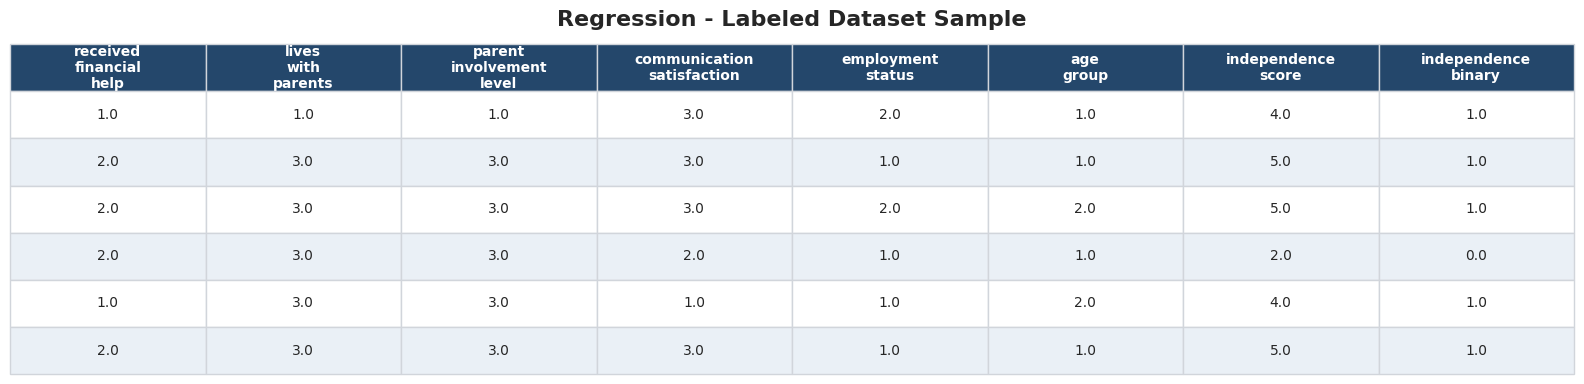

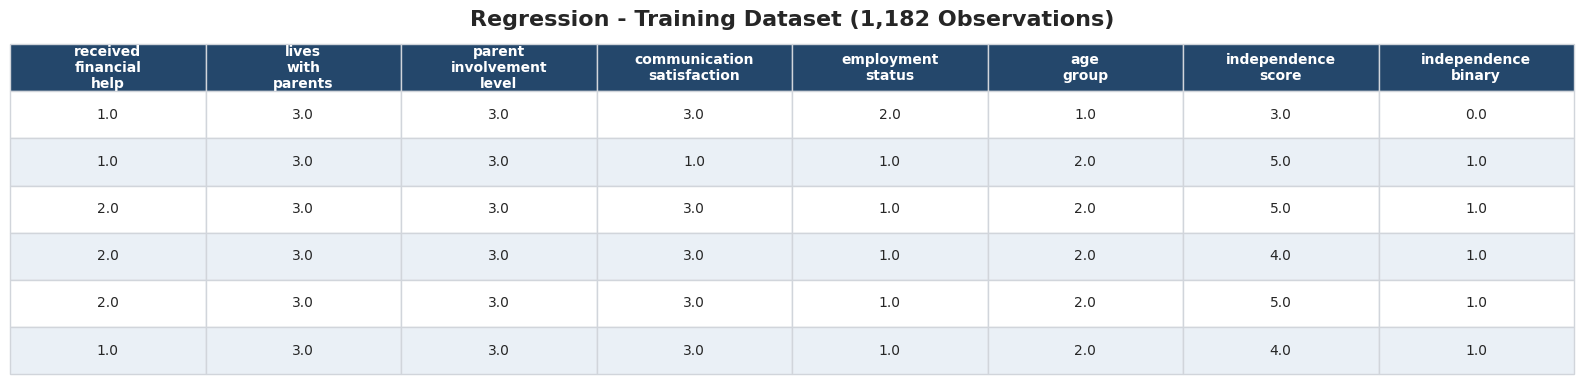

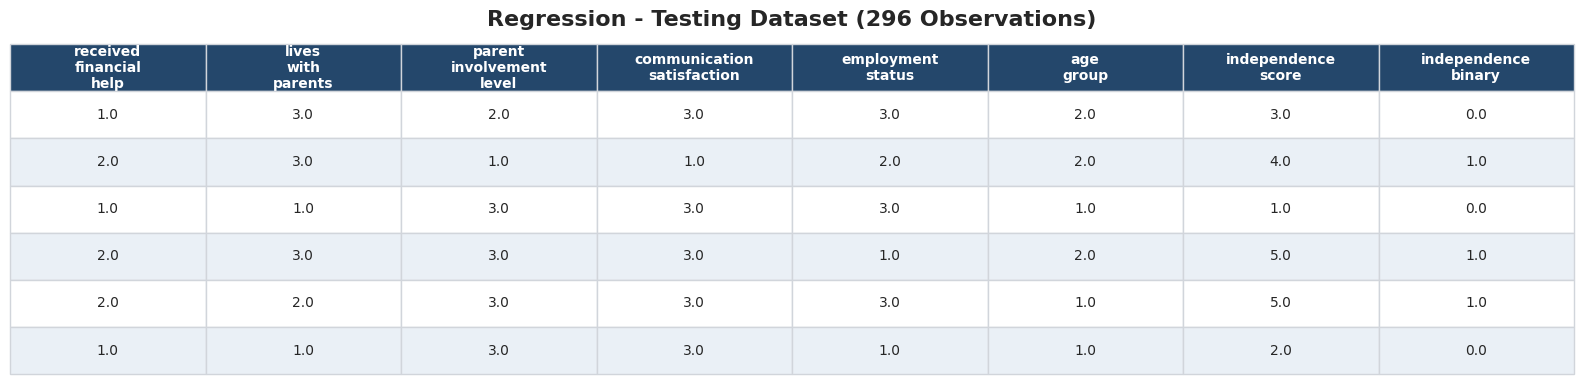

In [13]:
# Image 1: Complete labeled dataset
save_table_image(
    regression_data,
    "Regression - Labeled Dataset Sample",
    "regression_labeled_sample.png"
)

# Image 2: Training dataset
save_table_image(
    regression_train,
    "Regression - Training Dataset (1,182 Observations)",
    "regression_training_sample.png"
)

# Image 3: Testing dataset
save_table_image(
    regression_test,
    "Regression - Testing Dataset (296 Observations)",
    "regression_testing_sample.png"
)

## 8. Before-and-After One-Hot Encoding

The codes for the original categorial survey variables
are compared to their one-hot coded equivalents.

A single binary indicator is used to code each
non-reference variable category, with a value of 1
indicating the presence and a 0 indicating the absence.

This method transforms six original predictors into
twelve binary predictors.

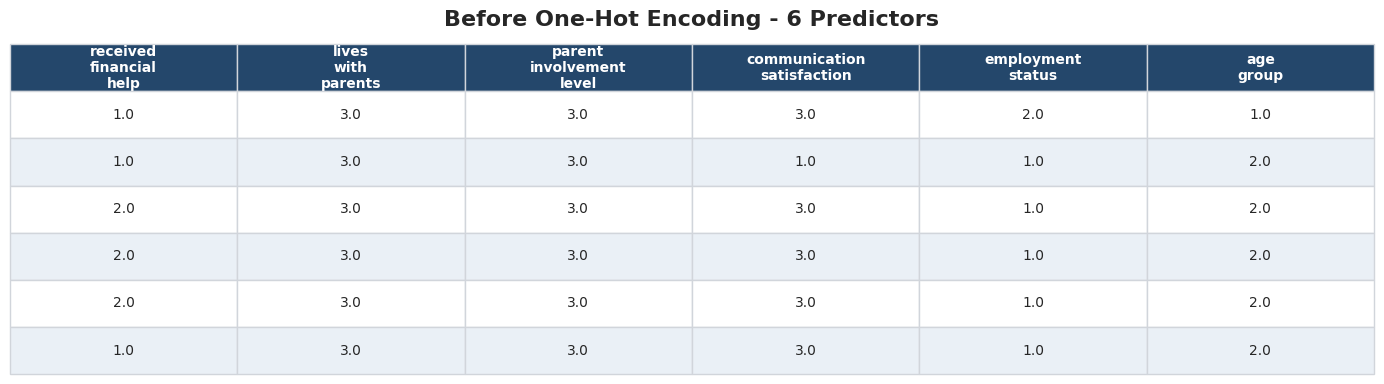

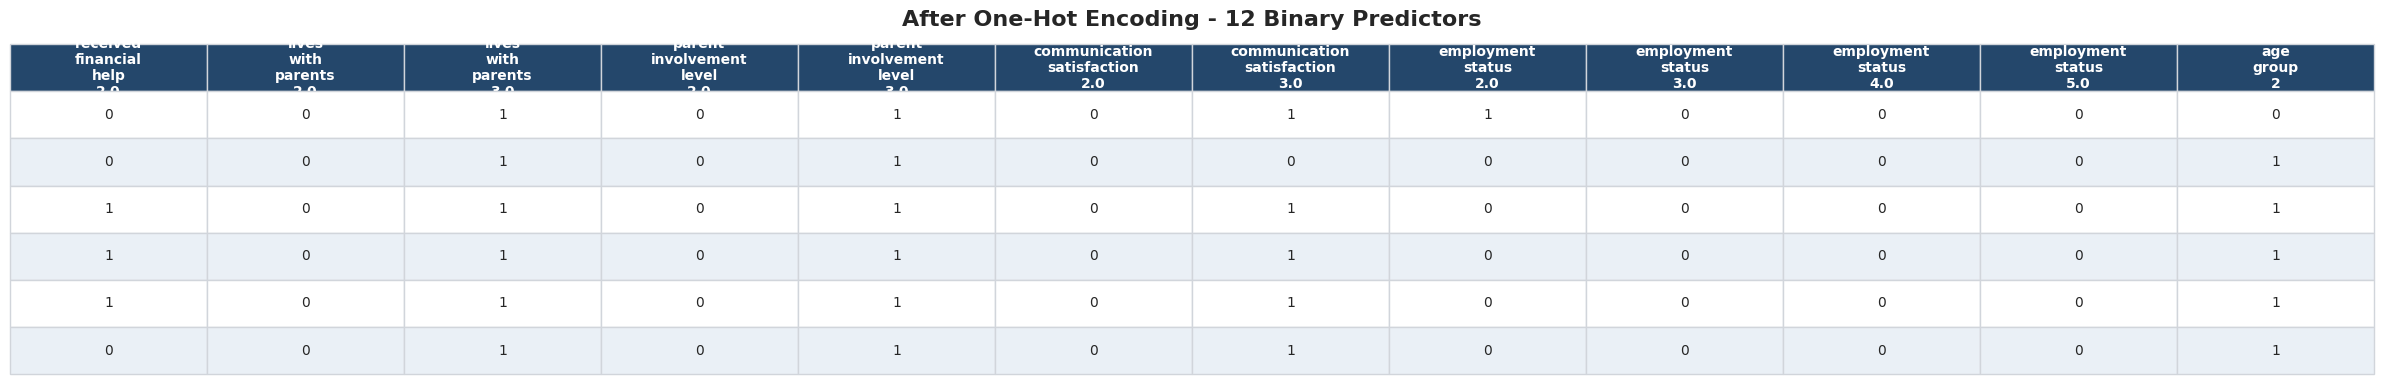

In [14]:
# Before one-hot encoding
save_table_image(
    X_train,
    "Before One-Hot Encoding - 6 Predictors",
    "regression_before_encoding.png"
)

# After one-hot encoding
save_table_image(
    X_train_encoded.astype(int),
    "After One-Hot Encoding - 12 Binary Predictors",
    "regression_after_encoding.png"
)

In [15]:
print("Generated Regression Files:\n")

for filename in sorted(os.listdir(".")):
    if filename.startswith("regression_"):
        print(filename)

Generated Regression Files:

regression_after_encoding.png
regression_before_encoding.png
regression_encoded_testing_data.csv
regression_encoded_training_data.csv
regression_labeled_data.csv
regression_labeled_sample.png
regression_testing_data.csv
regression_testing_sample.png
regression_training_data.csv
regression_training_sample.png


## 9. Linear Regression Modeling

Linear regression is used to predict the score of financial
independence of young adults, which is measured from 1 to 5,
with larger scores corresponding to higher levels of financial independence.

This model is built by using 1,182 observations and tested on 296 testing observations.

Performance of the model is assessed in terms of Root Mean Squared
Error (RMSE), Mean Absolute Error (MAE) and R-squared.

In [16]:

linear_model = LinearRegression()


linear_model.fit(
    X_train_encoded,
    y_linear_train
)


y_linear_pred = linear_model.predict(X_test_encoded)


linear_rmse = np.sqrt(
    mean_squared_error(y_linear_test, y_linear_pred)
)

linear_mae = mean_absolute_error(
    y_linear_test, y_linear_pred
)

linear_r2 = r2_score(
    y_linear_test, y_linear_pred
)

print("Linear Regression Results")
print("=" * 40)

print(f"RMSE: {linear_rmse:.4f}")
print(f"MAE: {linear_mae:.4f}")
print(f"R-squared: {linear_r2:.4f}")
print(f"Intercept: {linear_model.intercept_:.4f}")

Linear Regression Results
RMSE: 0.8788
MAE: 0.5815
R-squared: 0.5025
Intercept: 2.7219


### Linear Regression Results

The Linear Regression model had an RMSE of 0.8788,
an MAE of 0.5815, and an R-squared value of 0.5025 on
the testing data set.

The MAE value suggests that the predictions of financial
independence scores deviate from the true values by 0.58 on
average on a scale from 1 to 5.

The R-squared value is a representation of how much of the
variation in the financial independence scores can be explained
by the model, which is around 50.25%.

The intercept of 2.7219 is the value of the financial
independence score if all predictors were at their reference
categories.

This shows that there was enough predictive information in
selected demographic, financial, and family-related predictors
for young adult independence. However, these associations are
not causal.

## 10. Actual vs. Predicted Values

A scatter plot is utilized for comparison between the real financial
independence values and the predicted values using the Linear Regression model.

The reference line is the diagonal line, which shows perfect prediction.
The further the points from this line, the greater the prediction error.

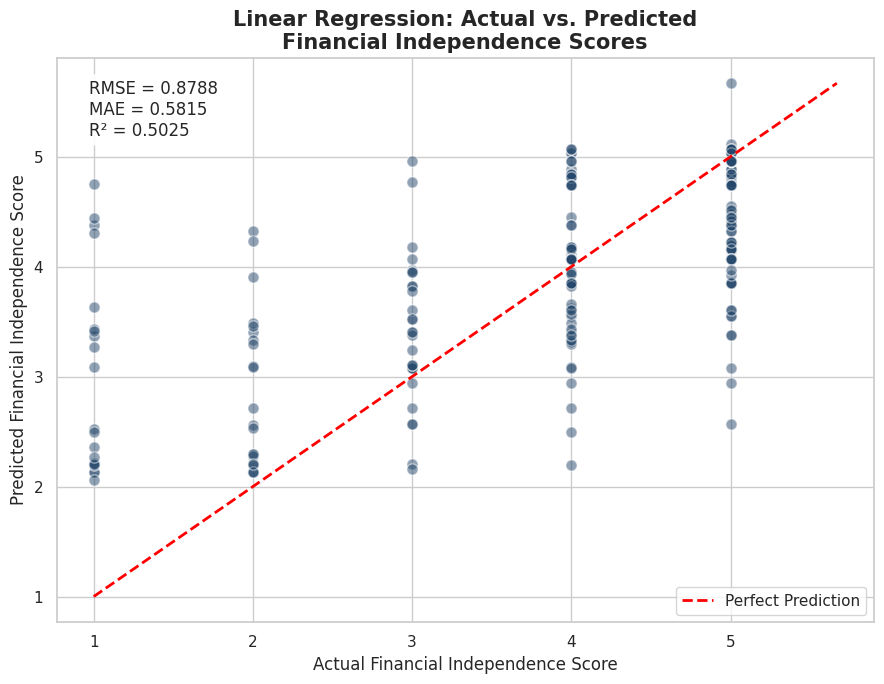

In [17]:
# Actual vs. Predicted Values
plt.figure(figsize=(9, 7))

plt.scatter(
    y_linear_test,
    y_linear_pred,
    alpha=0.5,
    color="#24476B",
    edgecolors="white",
    s=65
)


lower = min(y_linear_test.min(), y_linear_pred.min())
upper = max(y_linear_test.max(), y_linear_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title(
    "Linear Regression: Actual vs. Predicted\n"
    "Financial Independence Scores",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Actual Financial Independence Score", fontsize=12)
plt.ylabel("Predicted Financial Independence Score", fontsize=12)

plt.xticks([1, 2, 3, 4, 5])

plt.text(
    0.04, 0.96,
    f"RMSE = {linear_rmse:.4f}\n"
    f"MAE = {linear_mae:.4f}\n"
    f"R² = {linear_r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.9
    )
)

plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "regression_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Linear Regression Coefficient Analysis

Regression coefficients are evaluated in order to see
the relationship between individual categorical predictors
and scores for financial independence.

Due to the one-hot encoding used, the coefficients show
the predicted differences in the financial independence
score compared to the reference category.

Positive coefficients mean that there will be higher
predicted independence score, while negative coefficients
will give lower independence scores.

In [18]:

linear_coefficients = pd.DataFrame({
    "Feature": encoded_features,
    "Coefficient": linear_model.coef_
})


linear_coefficients["Absolute_Coefficient"] = (
    linear_coefficients["Coefficient"].abs()
)


linear_coefficients = linear_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

print("Linear Regression Coefficients:")
display(linear_coefficients.round(4))

print("\nReference Categories:")

for feature, categories in zip(features, encoder.categories_):
    print(f"{feature}: {categories[0]}")


linear_coefficients.to_csv(
    "regression_linear_coefficients.csv",
    index=False
)

Linear Regression Coefficients:


,Feature,Coefficient,Absolute_Coefficient
0,lives_with_parents_3.0,1.1354,1.1354
1,employment_status_5.0,0.9273,0.9273
2,received_financial_help_2.0,0.8893,0.8893
3,employment_status_3.0,-0.5838,0.5838
4,employment_status_4.0,-0.5472,0.5472
5,employment_status_2.0,-0.5181,0.5181
6,lives_with_parents_2.0,0.3612,0.3612
7,age_group_2,0.2223,0.2223
8,communication_satisfaction_2.0,0.1433,0.1433
9,parent_involvement_level_3.0,-0.0788,0.0788



Reference Categories:
received_financial_help: 1.0
lives_with_parents: 1.0
parent_involvement_level: 1.0
communication_satisfaction: 1.0
employment_status: 1.0
age_group: 1


In [19]:


for feature in features:

    mapping = df_clean[
        ["respondent_id", feature]
    ].merge(
        df_labeled[["respondent_id", feature]],
        on="respondent_id",
        suffixes=("_numeric", "_label"),
        validate="one_to_one"
    )

    print("\n" + "=" * 60)
    print(feature)

    display(pd.crosstab(
        mapping[f"{feature}_numeric"],
        mapping[f"{feature}_label"]
    ))


received_financial_help


received_financial_help_label,No,Yes
received_financial_help_numeric,,
1.0,0,577
2.0,918,0



lives_with_parents


lives_with_parents_label,Does not live with a parent,Lives with all parents,Lives with at least one parent
lives_with_parents_numeric,,,
1.0,0,219,0
2.0,0,0,149
3.0,1125,0,0



parent_involvement_level


parent_involvement_level_label,As involved as desired,Less involved than desired,More involved than desired
parent_involvement_level_numeric,,,
1.0,0,0,124
2.0,0,320,0
3.0,1044,0,0


... (2 outputs left out)


employment_status


employment_status_label,Not currently working for pay,Retired,Unable to work due to disability,Working full time,Working part time
employment_status_numeric,,,,,
1.0,0,0,0,1031,0
2.0,0,0,0,0,216
3.0,218,0,0,0,0
4.0,0,0,25,0,0
5.0,0,2,0,0,0



age_group


age_group_label,18–29,30–34
age_group_numeric,,
1,747,0
2,0,748


### Interpretation of Linear Regression Coefficients

**1. Part-Time Work (-0.5181)**

Young adults employed in part-time work are expected to have financial independence scores 0.52 points
less than those working on a full-time basis, keeping all other predictor variables unchanged.

**2. Unpaid Work (-0.5838)**

Young adults who are unemployed for monetary remuneration are expected to have financial
independence scores 0.58 points less than those who are working on a full-time basis, keeping all other
predictors unchanged.

**3. Age Category (+0.2223)**

Young adults in age category 30-34 are expected to have financial independence scores 0.22 points more
than those in the age group of 18-29, keeping all other predictor variables unchanged.

This implies that the employment status and age of young adults are correlated with financial
independence. However, correlation does not imply causation.

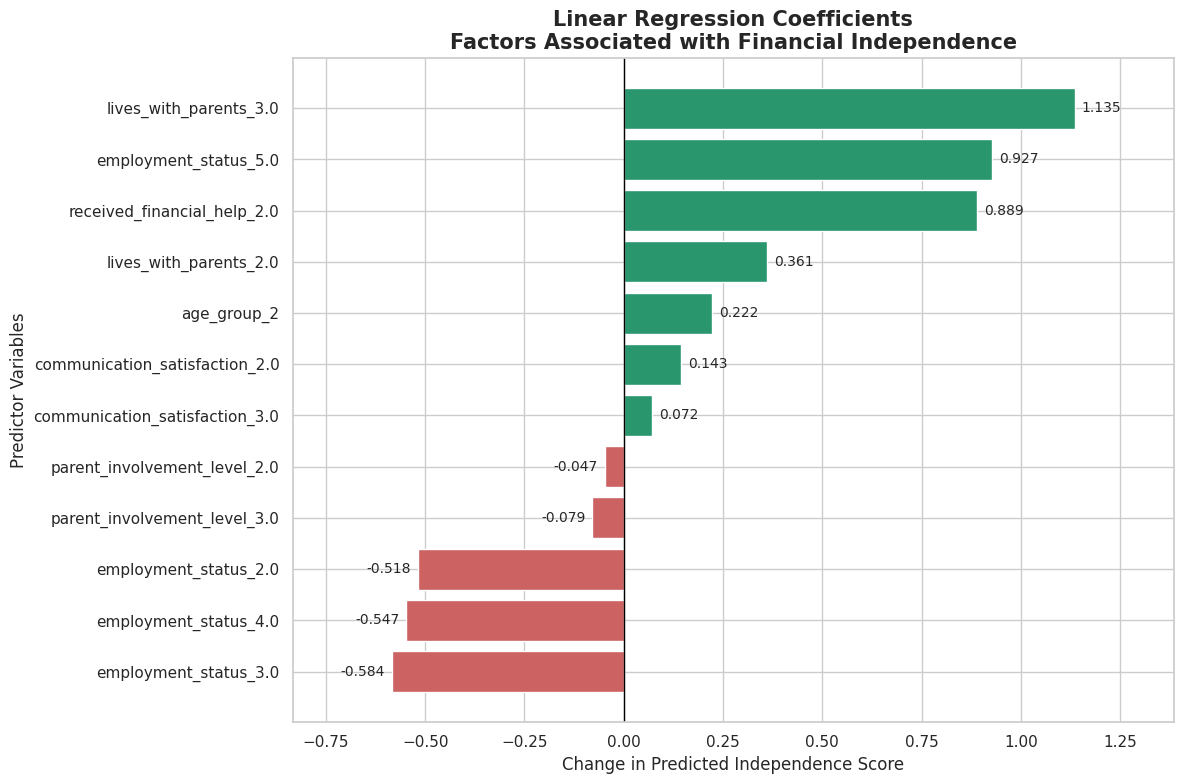

In [20]:
# Sort coefficients for visualization
plot_coef = linear_coefficients.sort_values(
    "Coefficient"
)

colors = [
    "#29966E" if value > 0 else "#CC6262"
    for value in plot_coef["Coefficient"]
]

plt.figure(figsize=(12, 8))

bars = plt.barh(
    plot_coef["Feature"],
    plot_coef["Coefficient"],
    color=colors
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=5,
    fontsize=10
)

plt.title(
    "Linear Regression Coefficients\n"
    "Factors Associated with Financial Independence",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Change in Predicted Independence Score"
)

plt.ylabel("Predictor Variables")

plt.xlim(
    plot_coef["Coefficient"].min() - 0.25,
    plot_coef["Coefficient"].max() + 0.25
)

plt.tight_layout()

plt.savefig(
    "regression_linear_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Logistic Regression Modeling

The Logistic Regression algorithm is employed to classify
whether the adult is high or low on the financial independence axis.

The logistic regression algorithm employs the twelve
one-hot encoded predictor variables to predict the probability
of belonging to the high financial independence class.

Classification is done based on a threshold value of 0.5.
The performance metrics are accuracy, precision, recall,
F1 score, and confusion matrix. Calculation of the majority
class baseline is necessary since there are imbalances in
the class distribution of the target variable.

In [21]:

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)


logistic_model.fit(
    X_train_encoded,
    y_logistic_train
)


y_logistic_pred = logistic_model.predict(
    X_test_encoded
)


y_logistic_prob = logistic_model.predict_proba(
    X_test_encoded
)[:, 1]


logistic_accuracy = accuracy_score(
    y_logistic_test,
    y_logistic_pred
)


logistic_cm = confusion_matrix(
    y_logistic_test,
    y_logistic_pred,
    labels=[0, 1]
)


majority_class = y_logistic_train.mode()[0]

baseline_predictions = np.full(
    len(y_logistic_test),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_logistic_test,
    baseline_predictions
)


print("Logistic Regression Results")
print("=" * 45)

print(f"Test Accuracy: {logistic_accuracy:.4f}")
print(f"Test Accuracy (%): {logistic_accuracy * 100:.2f}%")
print(f"Majority Baseline: {baseline_accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(logistic_cm)

print("\nClassification Report:")
print(classification_report(
    y_logistic_test,
    y_logistic_pred,
    labels=[0, 1],
    target_names=[
        "Lower Independence",
        "High Independence"
    ],
    zero_division=0
))

Logistic Regression Results
Test Accuracy: 0.8682
Test Accuracy (%): 86.82%
Majority Baseline: 76.01%

Confusion Matrix:
[[ 45  26]
 [ 13 212]]

Classification Report:
                    precision    recall  f1-score   support

Lower Independence       0.78      0.63      0.70        71
 High Independence       0.89      0.94      0.92       225

          accuracy                           0.87       296
         macro avg       0.83      0.79      0.81       296
      weighted avg       0.86      0.87      0.86       296



### Logistic Regression Results

Logistic Regression Model demonstrated 86.82%
accuracy in testing by predicting 257 out of 296 data points.

It surpassed the accuracy level of the majority class,
which was 76.01%, by 10.81%.

From the confusion matrix, one can conclude that 45 data
points with low independence and 212 data points with high
independence were predicted correctly.

However, 26 data points with low independence were
wrongly categorized as the high-independence category and
vice versa.

The model demonstrated the recall value of 94% for the
high financial independence and 63% for the low financial
independence.

The analysis shows that the model demonstrates better
performance on the majority class identification. Thus,
accuracy does not reflect its overall prediction performance.

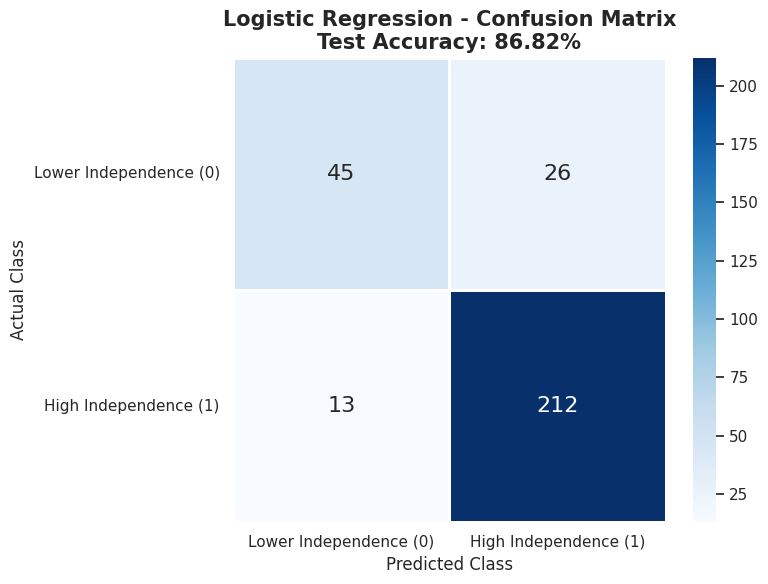

In [22]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    xticklabels=[
        "Lower Independence (0)",
        "High Independence (1)"
    ],
    yticklabels=[
        "Lower Independence (0)",
        "High Independence (1)"
    ],
    annot_kws={"size": 16}
)

plt.title(
    "Logistic Regression - Confusion Matrix\n"
    f"Test Accuracy: {logistic_accuracy * 100:.2f}%",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "regression_logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 13. Logistic Regression Coefficients and Odds Ratios

Coefficients from Logistic Regression signify the
change in log-odds of being part of the
high financial independence group.

The exponent of each coefficient is computed to get
its odds ratio.

Given that the independent variables are in one-hot
encoding form, each odds ratio is a comparison
between a predictor level and its respective reference
level, keeping other predictors constant.

An odds ratio above one is associated with high
odds of being financially independent, while an odds
ratio below one means low odds of financial
independence.

In [23]:

logistic_coefficients = pd.DataFrame({
    "Feature": encoded_features,
    "Coefficient": logistic_model.coef_[0]
})


logistic_coefficients["Odds_Ratio"] = np.exp(
    logistic_coefficients["Coefficient"]
)


logistic_coefficients["Odds_Change_Percent"] = (
    logistic_coefficients["Odds_Ratio"] - 1
) * 100


logistic_coefficients["Absolute_Coefficient"] = (
    logistic_coefficients["Coefficient"].abs()
)


logistic_coefficients = logistic_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

print("Logistic Regression Coefficients and Odds Ratios:")

display(logistic_coefficients.round(4))

print("\nReference Categories:")

for feature, categories in zip(features, encoder.categories_):
    print(f"{feature}: {categories[0]}")


logistic_coefficients.to_csv(
    "regression_logistic_coefficients.csv",
    index=False
)

Logistic Regression Coefficients and Odds Ratios:


,Feature,Coefficient,Odds_Ratio,Odds_Change_Percent,Absolute_Coefficient
0,lives_with_parents_3.0,2.4958,12.1311,1113.1125,2.4958
1,received_financial_help_2.0,1.6170,5.0378,403.7792,1.6170
2,employment_status_3.0,-1.4531,0.2338,-76.6155,1.4531
3,employment_status_2.0,-1.3301,0.2645,-73.5544,1.3301
4,communication_satisfaction_2.0,0.6313,1.8800,88.0005,0.6313
5,age_group_2,0.5176,1.6780,67.7985,0.5176
6,employment_status_4.0,-0.5116,0.5996,-40.0448,0.5116
7,lives_with_parents_2.0,0.3792,1.4612,46.1177,0.3792
8,communication_satisfaction_3.0,0.2396,1.2707,27.0716,0.2396
9,parent_involvement_level_2.0,-0.1473,0.8630,-13.6971,0.1473



Reference Categories:
received_financial_help: 1.0
lives_with_parents: 1.0
parent_involvement_level: 1.0
communication_satisfaction: 1.0
employment_status: 1.0
age_group: 1


### Interpretation of Logistic Regression Odds Ratios

**1. Part-Time Work**

Coefficient: -1.3301
Odds Ratio: 0.2645

Young people employed in part-time jobs have about
73.55% fewer predicted odds of being financially
independent compared to young people working full time,
controlling for all other predictors.

**2. No Job**

Coefficient: -1.4531
Odds Ratio: 0.2338

Young people without paid work have about 76.62% fewer
predicted odds of being financially independent compared
to young people working full time, controlling for all
other predictors.

**3. Age**

Coefficient: 0.5176
Odds Ratio: 1.6780

Young people between ages 30-34 have 67.80% higher
predicted odds of being financially independent than
young people between 18-29, controlling for all other
predictors.

The above results show that both employment status
and age relate to financial independence of young
people. These associations, however, do not indicate
causality. Changes in odds should not be confused
with changes in probabilities.

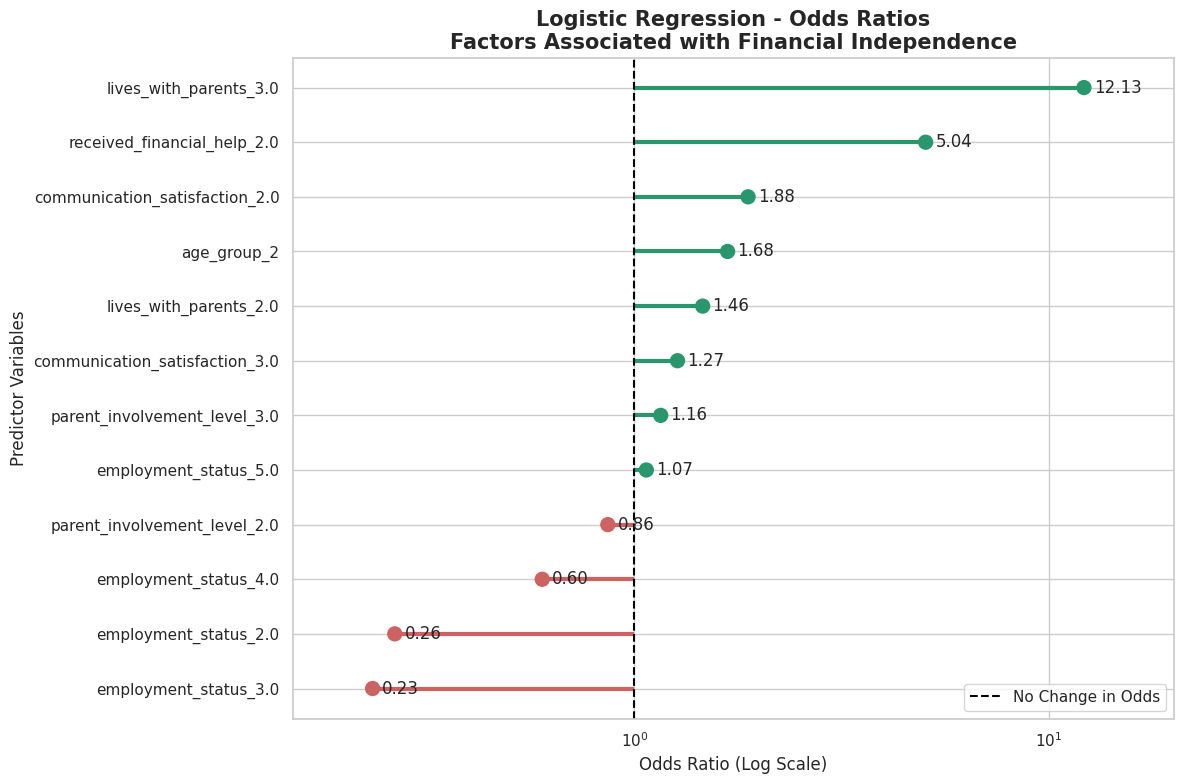

In [24]:

odds_plot = logistic_coefficients.sort_values(
    "Odds_Ratio"
)

colors = [
    "#29966E" if value > 1 else "#CC6262"
    for value in odds_plot["Odds_Ratio"]
]

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    odds_plot["Odds_Ratio"],
    odds_plot["Feature"],
    c=colors,
    s=100,
    zorder=3
)


for i, value in enumerate(odds_plot["Odds_Ratio"]):
    ax.hlines(
        y=i,
        xmin=min(1, value),
        xmax=max(1, value),
        color=colors[i],
        linewidth=3
    )

    ax.annotate(
        f"{value:.2f}",
        (value, i),
        xytext=(7, 0),
        textcoords="offset points",
        va="center"
    )


ax.axvline(
    x=1,
    color="black",
    linestyle="--",
    label="No Change in Odds"
)

ax.set_xscale("log")
ax.set_xlim(0.15, 20)

ax.set_title(
    "Logistic Regression - Odds Ratios\n"
    "Factors Associated with Financial Independence",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Odds Ratio (Log Scale)")
ax.set_ylabel("Predictor Variables")

ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    "regression_logistic_odds_ratios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 14. Comparison with Naive Bayes from Module 3

For the Multinomial Naive Bayes model in Module 3, an
accuracy of 59.12% was obtained during testing for five
classes of financial independence.

Logistic Regression in Module 4 yielded an accuracy
of 86.82% for a binary target.

These two results cannot be compared because each
model makes predictions for different number of classes.

In order to make a more accurate comparison,
the Multinomial Naive Bayes model is re-trained
using the same binary target, predictors, and
training/test sets as in the Logistic Regression model.

The same parameters as in Module 3,
alpha=1.0 and full one-hot encoding are used.

In [26]:
from sklearn.naive_bayes import MultinomialNB

nb_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


X_train_nb = nb_encoder.fit_transform(X_train)
X_test_nb = nb_encoder.transform(X_test)


nb_binary_model = MultinomialNB(alpha=1.0)

nb_binary_model.fit(
    X_train_nb,
    y_logistic_train
)


y_nb_binary_pred = nb_binary_model.predict(
    X_test_nb
)


nb_binary_accuracy = accuracy_score(
    y_logistic_test,
    y_nb_binary_pred
)


nb_binary_cm = confusion_matrix(
    y_logistic_test,
    y_nb_binary_pred,
    labels=[0, 1]
)

print("Binary Naive Bayes Results")
print("=" * 45)

print(f"Test Accuracy: {nb_binary_accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(nb_binary_cm)

print("\nClassification Report:")
print(classification_report(
    y_logistic_test,
    y_nb_binary_pred,
    labels=[0, 1],
    target_names=[
        "Lower Independence",
        "High Independence"
    ],
    zero_division=0
))

# Compare model accuracies
accuracy_difference = (
    logistic_accuracy - nb_binary_accuracy
) * 100

print("\nModel Comparison")
print("=" * 45)

print("Original Module 3 Naive Bayes: 59.12% (5 classes)")
print(f"Binary Naive Bayes: {nb_binary_accuracy * 100:.2f}%")
print(f"Logistic Regression: {logistic_accuracy * 100:.2f}%")
print(f"Accuracy Difference (LR - NB): {accuracy_difference:.2f} percentage points")

Binary Naive Bayes Results
Test Accuracy: 86.49%

Confusion Matrix:
[[ 49  22]
 [ 18 207]]

Classification Report:
                    precision    recall  f1-score   support

Lower Independence       0.73      0.69      0.71        71
 High Independence       0.90      0.92      0.91       225

          accuracy                           0.86       296
         macro avg       0.82      0.81      0.81       296
      weighted avg       0.86      0.86      0.86       296


Model Comparison
Original Module 3 Naive Bayes: 59.12% (5 classes)
Binary Naive Bayes: 86.49%
Logistic Regression: 86.82%
Accuracy Difference (LR - NB): 0.34 percentage points


### Model Comparison Results

The Multinomial Naive Bayes algorithm used in Module 3 gave an accuracy of 59.12% while making predictions on five categories of financial independence.

After applying Naive Bayes with the binary output and same observations for training and testing as Logistic Regression, the accuracy was 86.49%.

Logistic regression had an accuracy of 86.82%, which is more accurate than binary Naive Bayes by 0.34%.

Nevertheless, Logistic Regression successfully classified
only
one more testing example. Naive Bayes showed higher
recall – 69% among people with less financial
independence versus 63% of Logistic Regression.

Both algorithms surpassed the majority class baseline
of 76.01%.

It means that both models work well for binary financial
independence classification. However, none of them
demonstrates significant superiority over another one.

The initial accuracy of the five-class Naive Bayes
is not comparable to binary classification accuracy
because the prediction task is different.
Both models preserve their one-hot encoding method.

,Model,Accuracy,Accuracy_Percent
0,Majority-Class Baseline,0.7601,76.0135
1,Binary Naive Bayes,0.8649,86.4865
2,Logistic Regression,0.8682,86.8243


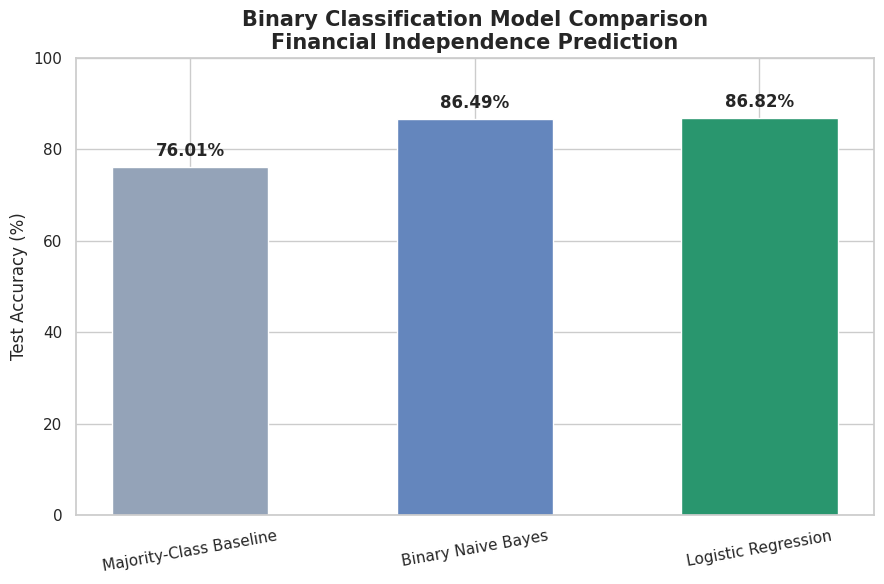

In [27]:
# Create model comparison table
regression_comparison = pd.DataFrame({
    "Model": [
        "Majority-Class Baseline",
        "Binary Naive Bayes",
        "Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        nb_binary_accuracy,
        logistic_accuracy
    ]
})

regression_comparison["Accuracy_Percent"] = (
    regression_comparison["Accuracy"] * 100
)

display(regression_comparison.round(4))

# Save comparison results
regression_comparison.to_csv(
    "regression_model_comparison.csv",
    index=False
)

# Generate comparison plot
plt.figure(figsize=(9, 6))

bars = plt.bar(
    regression_comparison["Model"],
    regression_comparison["Accuracy_Percent"],
    color=["#94A3B8", "#6486BD", "#29966E"],
    width=0.55
)

plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Binary Classification Model Comparison\n"
    "Financial Independence Prediction",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

plt.xticks(rotation=10)

plt.tight_layout()

plt.savefig(
    "regression_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Regression Conclusions

The linear regression analysis offers significant insight
into the variables that affect the independence of
young adults in terms of finances in the US.

The Linear Regression was able to attain an R-squared
value of 0.5025, RMSE of 0.8788, and MAE of 0.5815.
The obtained values imply that the chosen variables
explain about half of the variance of independence
scores of the sample being tested.

Coefficient analysis of the variables shows that job
status, living status, financial aid, and age
are some of the important variables associated with
financial independence of young people. Young people
who work part-time and not currently working for money
earn lower financial independence scores when compared
to those who work full-time.

In particular, the Logistic Regression model obtained a
testing accuracy of 86.82%, surpassing the binary
Multinomial Naive Bayes model that scored 86.49%.
However, Naive Bayes showed better results in
identifying respondents with low levels of financial

It can be concluded that financial independence is
dependent on various socioeconomic and family factors,
and not a single factor. Factors like employment,
financial aid, and cohabitation may prove to be
interesting variables in estimating financial
independence of young people.

There are several issues with the study. The first one
is the fact that the financial independence score is
an ordinal variable, but it is used in the numerical
form in Linear Regression. The second issue is related
to the simplification of the original five classes
into the binary one and the class imbalance present in
the dataset. The final issue is that the models do not
make use of survey weights.

In [28]:


regression_metrics = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Linear Regression",
        "Linear Regression",
        "Logistic Regression",
        "Binary Naive Bayes",
        "Majority-Class Baseline"
    ],
    "Metric": [
        "RMSE",
        "MAE",
        "R-squared",
        "Accuracy",
        "Accuracy",
        "Accuracy"
    ],
    "Value": [
        linear_rmse,
        linear_mae,
        linear_r2,
        logistic_accuracy,
        nb_binary_accuracy,
        baseline_accuracy
    ]
})

display(regression_metrics.round(4))

regression_metrics.to_csv(
    "regression_evaluation_metrics.csv",
    index=False
)

print("Final regression results saved successfully!")

,Model,Metric,Value
0,Linear Regression,RMSE,0.8788
1,Linear Regression,MAE,0.5815
2,Linear Regression,R-squared,0.5025
3,Logistic Regression,Accuracy,0.8682
4,Binary Naive Bayes,Accuracy,0.8649
5,Majority-Class Baseline,Accuracy,0.7601


Final regression results saved successfully!


In [29]:
regression_files = sorted([
    filename
    for filename in os.listdir(".")
    if filename.startswith("regression_")
    and filename.endswith((".csv", ".png"))
])

for i, filename in enumerate(regression_files, 1):
    print(f"{i}. {filename}")

print(f"\nTotal files: {len(regression_files)}")

1. regression_actual_vs_predicted.png
2. regression_after_encoding.png
3. regression_before_encoding.png
4. regression_encoded_testing_data.csv
5. regression_encoded_training_data.csv
6. regression_evaluation_metrics.csv
7. regression_labeled_data.csv
8. regression_labeled_sample.png
9. regression_linear_coefficients.csv
10. regression_linear_coefficients.png
11. regression_logistic_coefficients.csv
12. regression_logistic_confusion_matrix.png
13. regression_logistic_odds_ratios.png
14. regression_model_comparison.csv
15. regression_model_comparison.png
16. regression_testing_data.csv
17. regression_testing_sample.png
18. regression_training_data.csv
19. regression_training_sample.png

Total files: 19


In [30]:
import zipfile
from google.colab import files

zip_filename = "Module4_Regression_Files.zip"

with zipfile.ZipFile(
    zip_filename, "w", zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in regression_files:
        zip_file.write(filename)

print(f"ZIP file created: {zip_filename}")
print(f"Total files included: {len(regression_files)}")

files.download(zip_filename)

ZIP file created: Module4_Regression_Files.zip
Total files included: 19


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>